In [1]:
import os, sys, json, time, hashlib, random
from datetime import datetime

# ---- Mount Drive -----------------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = '/content/drive/MyDrive/AISL_data'
    ON_COLAB = True
except Exception as e:
    ROOT = os.path.abspath('./AISL_data')
    ON_COLAB = False
    print('Not on Colab -> local root:', ROOT, '|', e)

# ---- Directory scaffold (ALL persistent paths live under ROOT) --------------
DIRS = {k: os.path.join(ROOT, v) for k, v in {
    'data':'microdata', 'fig':'figures', 'tab':'tables', 'ckpt':'checkpoints',
    'log':'logs', 'hf':'cache/hf', 'torch':'cache/torch',
}.items()}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

FIGDIR, TABDIR, CKPTDIR, LOGDIR = DIRS['fig'], DIRS['tab'], DIRS['ckpt'], DIRS['log']

# ---- Point every library cache at Drive so downloads happen ONCE -----------
os.environ['HF_HOME']            = DIRS['hf']
os.environ['HF_DATASETS_CACHE']  = os.path.join(DIRS['hf'], 'datasets')
os.environ['TORCH_HOME']         = DIRS['torch']
TORCH_DATA = DIRS['torch']

print('ROOT      :', ROOT)
print('on Colab  :', ON_COLAB)
for k, v in DIRS.items():
    print(f'  {k:6s} -> {v}')

Mounted at /content/drive
ROOT      : /content/drive/MyDrive/AISL_data
on Colab  : True
  data   -> /content/drive/MyDrive/AISL_data/microdata
  fig    -> /content/drive/MyDrive/AISL_data/figures
  tab    -> /content/drive/MyDrive/AISL_data/tables
  ckpt   -> /content/drive/MyDrive/AISL_data/checkpoints
  log    -> /content/drive/MyDrive/AISL_data/logs
  hf     -> /content/drive/MyDrive/AISL_data/cache/hf
  torch  -> /content/drive/MyDrive/AISL_data/cache/torch


In [2]:
# ---- Reproducibility -------------------------------------------------------
SEED = 20260817
import numpy as np
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except Exception:
    pass
print('seed =', SEED)

seed = 20260817


In [3]:
STATUS_PATH = os.path.join(LOGDIR, 'status.json')

def _load_status():
    if os.path.exists(STATUS_PATH):
        try:
            with open(STATUS_PATH) as f: return json.load(f)
        except Exception:
            pass
    return {}

def _save_status(st):
    tmp = STATUS_PATH + '.tmp'
    with open(tmp, 'w') as f: json.dump(st, f, indent=2, sort_keys=True)
    os.replace(tmp, STATUS_PATH)          # atomic; survives an interrupted write

STATUS = _load_status()

def stage_done(name):
    return STATUS.get(name, {}).get('state') == 'ok'

def mark(name, state='ok', **payload):
    STATUS[name] = {'state': state, 'ts': datetime.now().isoformat(timespec='seconds'),
                    **payload}
    _save_status(STATUS)
    icon = {'ok':'[OK]','failed':'[FAIL]','skipped':'[SKIP]'}.get(state,'[..]')
    print(f'{icon} {name}', {k:v for k,v in payload.items() if k != 'traceback'})

def reset_stage(name=None):
    global STATUS
    if name is None: STATUS = {}
    else: STATUS.pop(name, None)
    _save_status(STATUS); print('reset:', name or 'ALL')

# ---- Results registry: every number the manuscript quotes is recorded here --
RESULTS_PATH = os.path.join(TABDIR, 'aisl_results.json')

def _load_results():
    if os.path.exists(RESULTS_PATH):
        try:
            with open(RESULTS_PATH) as f: return json.load(f)
        except Exception: pass
    return {}

RESULTS = _load_results()

def record(**kv):
    RESULTS.update(kv)
    tmp = RESULTS_PATH + '.tmp'
    with open(tmp,'w') as f: json.dump(RESULTS, f, indent=2, sort_keys=True)
    os.replace(tmp, RESULTS_PATH)

def status_report():
    import pandas as pd
    if not STATUS:
        print('no stages recorded yet'); return
    rows = [{'stage':k, 'state':v.get('state'), 'when':v.get('ts'),
             'detail':', '.join(f'{a}={b}' for a,b in v.items()
                                if a not in ('state','ts','traceback'))[:70]}
            for k,v in sorted(STATUS.items())]
    return pd.DataFrame(rows)

print('status file:', STATUS_PATH)
print('stages already complete:', [k for k in STATUS if stage_done(k)] or '(none)')

status file: /content/drive/MyDrive/AISL_data/logs/status.json
stages already complete: (none)


In [4]:
# ---- Plotting: every figure goes to Drive ---------------------------------
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':300,'savefig.dpi':300,
                     'font.size':11,'axes.titlesize':12,'figure.autolayout':True})

def savefig(name):
    # Write a 300-dpi JPG into the Drive figures/ dir, then verify it landed.
    path = os.path.join(FIGDIR, name + '.jpg')
    plt.savefig(path, dpi=300, format='jpg', bbox_inches='tight',
                pil_kwargs={'quality':95})
    ok = os.path.exists(path) and os.path.getsize(path) > 1024
    print(('saved  ' if ok else 'FAILED ') + path +
          (f'  ({os.path.getsize(path)//1024} KB)' if ok else ''))
    if not ok:
        raise IOError('figure did not persist to Drive: ' + path)
    return path

def savetable(df, name):
    p_csv = os.path.join(TABDIR, name + '.csv')
    df.to_csv(p_csv, index=False)
    print('saved ', p_csv)
    return p_csv

README.md:   0%|          | 0.00/4.22k [00:00<?, ?B/s]

prompts.jsonl: reconstructing file:   0%|          |  0.00B / 67.7MB            

prompts.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/99442 [00:00<?, ? examples/s]

corpus n=99442 | sampled=20000 | scored n=19906
mean=0.287 | p95=0.872 | max=0.991 | %>0.5=21.82
saved  /content/drive/MyDrive/AISL_data/figures/d3_rtp_toxicity.jpg  (169 KB)


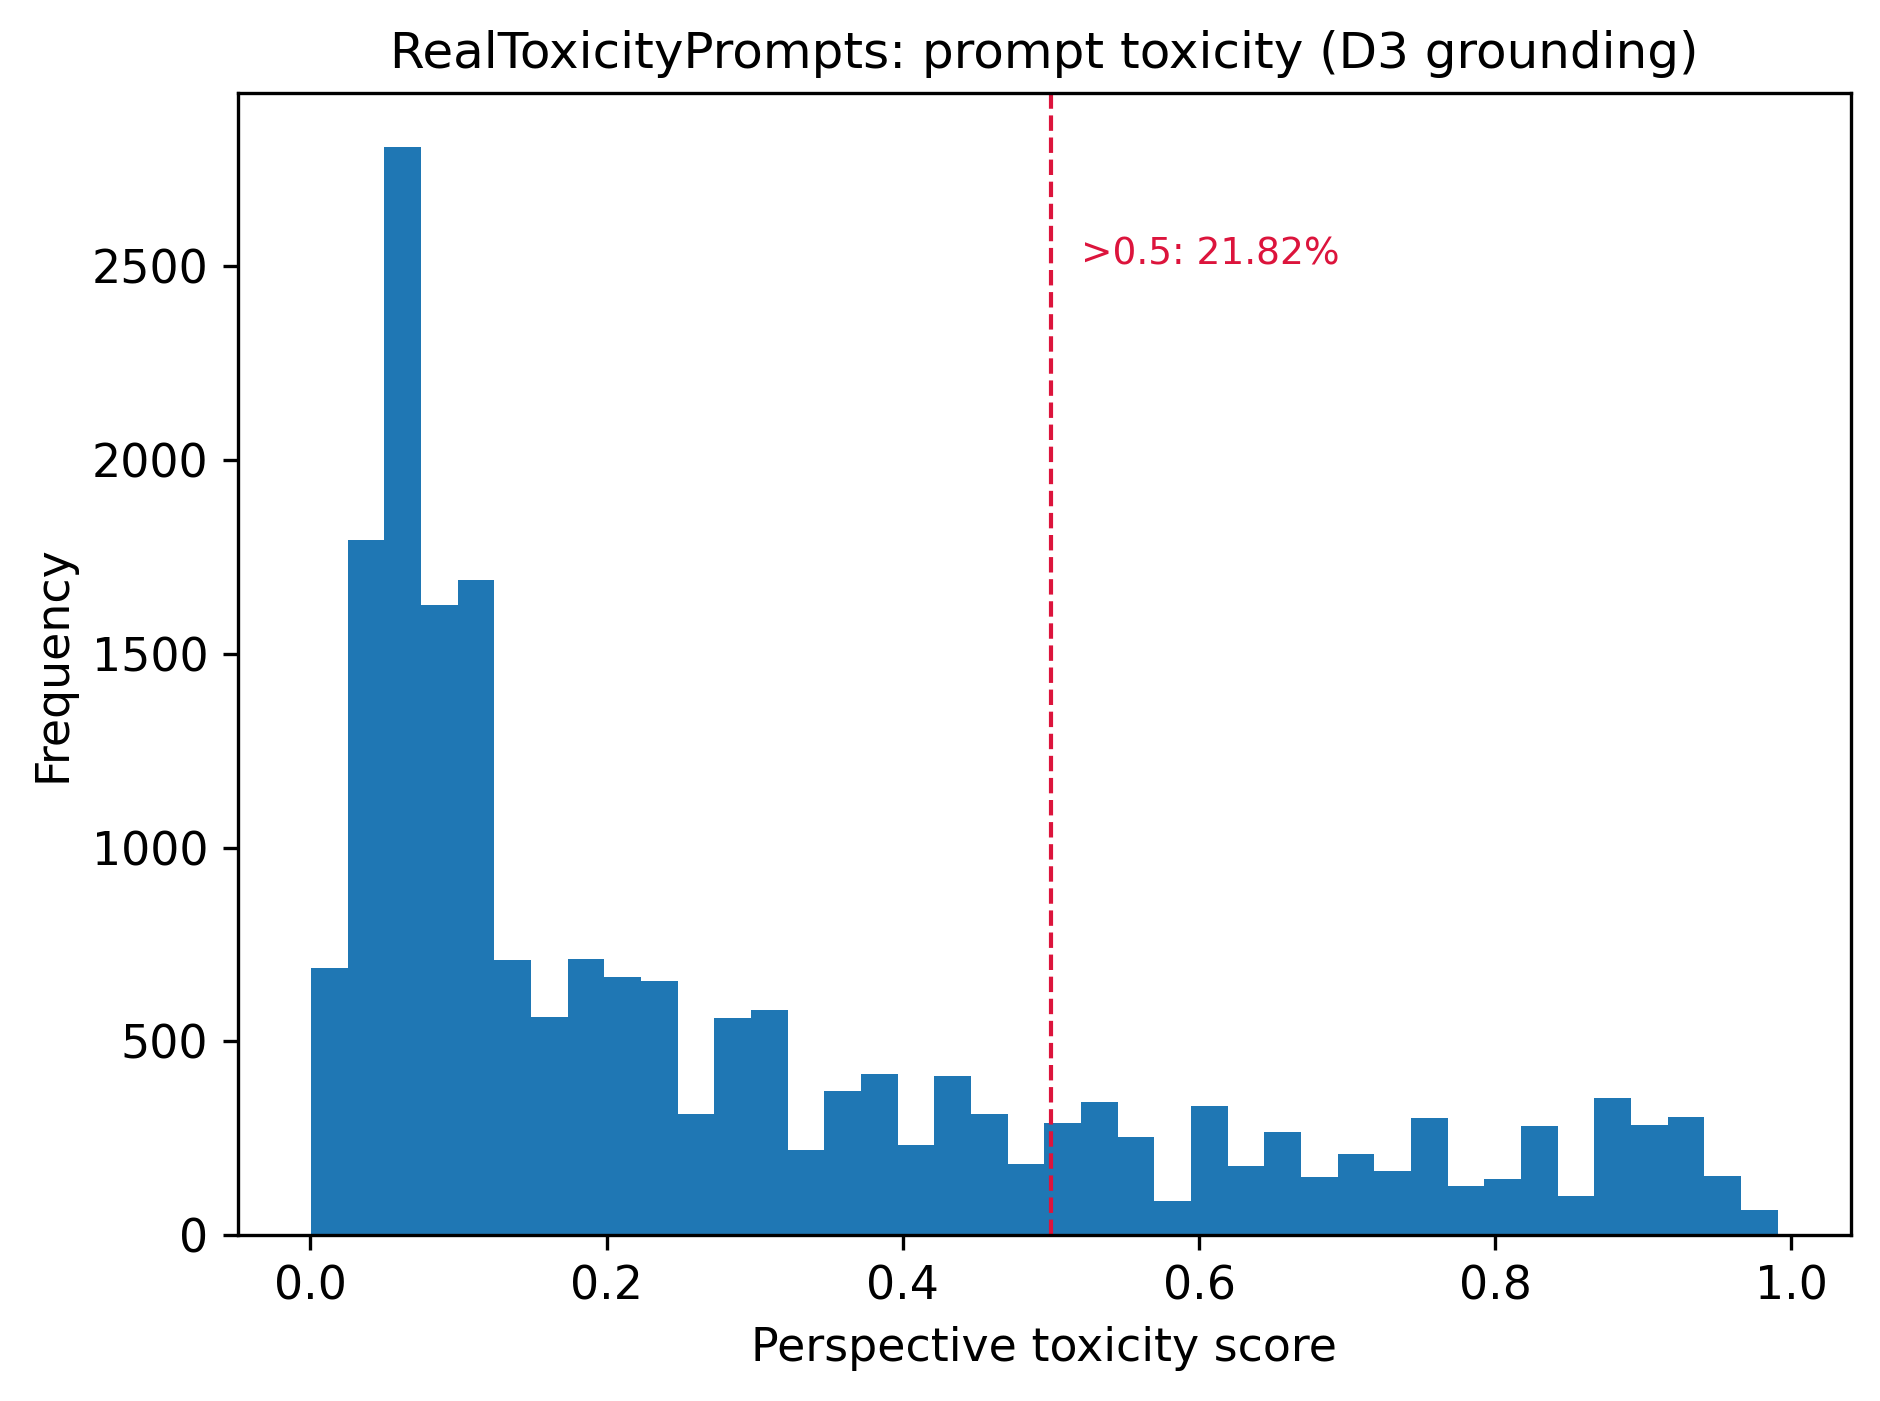

saved  /content/drive/MyDrive/AISL_data/tables/d3_rtp_summary.csv
[OK] d3_rtp {'n': 19906, 'mean': 0.287, 'secs': 7}


In [5]:
STAGE = 'd3_rtp'
if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d3_rtp_toxicity.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd
        from datasets import load_dataset
        t0 = time.time()
        rtp = load_dataset('allenai/real-toxicity-prompts', split='train',
                           cache_dir=os.environ['HF_DATASETS_CACHE'])
        N_TOTAL = len(rtp)
        N_SAMPLE = 20000
        idx = np.random.default_rng(SEED).choice(N_TOTAL, size=min(N_SAMPLE, N_TOTAL),
                                                 replace=False)
        sub = rtp.select(idx.tolist())
        tox = pd.Series([(r['prompt'] or {}).get('toxicity') for r in sub],
                        name='prompt_toxicity').dropna()

        n, mean, pct50 = len(tox), float(tox.mean()), float((tox > 0.5).mean()*100)
        p95, mx = float(tox.quantile(0.95)), float(tox.max())
        print(f'corpus n={N_TOTAL} | sampled={len(sub)} | scored n={n}')
        print(f'mean={mean:.3f} | p95={p95:.3f} | max={mx:.3f} | %>0.5={pct50:.2f}')

        plt.figure()
        ax = tox.plot(kind='hist', bins=40,
                      title='RealToxicityPrompts: prompt toxicity (D3 grounding)')
        ax.set_xlabel('Perspective toxicity score'); ax.set_ylabel('Frequency')
        ax.axvline(0.5, ls='--', lw=1, color='crimson')
        ax.annotate(f'>0.5: {pct50:.2f}%', xy=(0.52, ax.get_ylim()[1]*0.85),
                    fontsize=9, color='crimson')
        savefig('d3_rtp_toxicity'); plt.show()

        savetable(tox.describe().to_frame().reset_index(), 'd3_rtp_summary')
        record(d3_corpus_n=N_TOTAL, d3_n=n, d3_mean=round(mean,3),
               d3_pct_above_half=round(pct50,2), d3_p95=round(p95,3),
               d3_max=round(mx,3), d3_seed=SEED)
        mark(STAGE, n=n, mean=round(mean,3), secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); raise

README.md:   0%|          | 0.00/9.59k [00:00<?, ?B/s]

generation/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  223kB            

generation/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/817 [00:00<?, ? examples/s]

n questions=817 | n categories=38 | largest=Misconceptions (100)
saved  /content/drive/MyDrive/AISL_data/figures/d4_truthfulqa_categories.jpg  (248 KB)


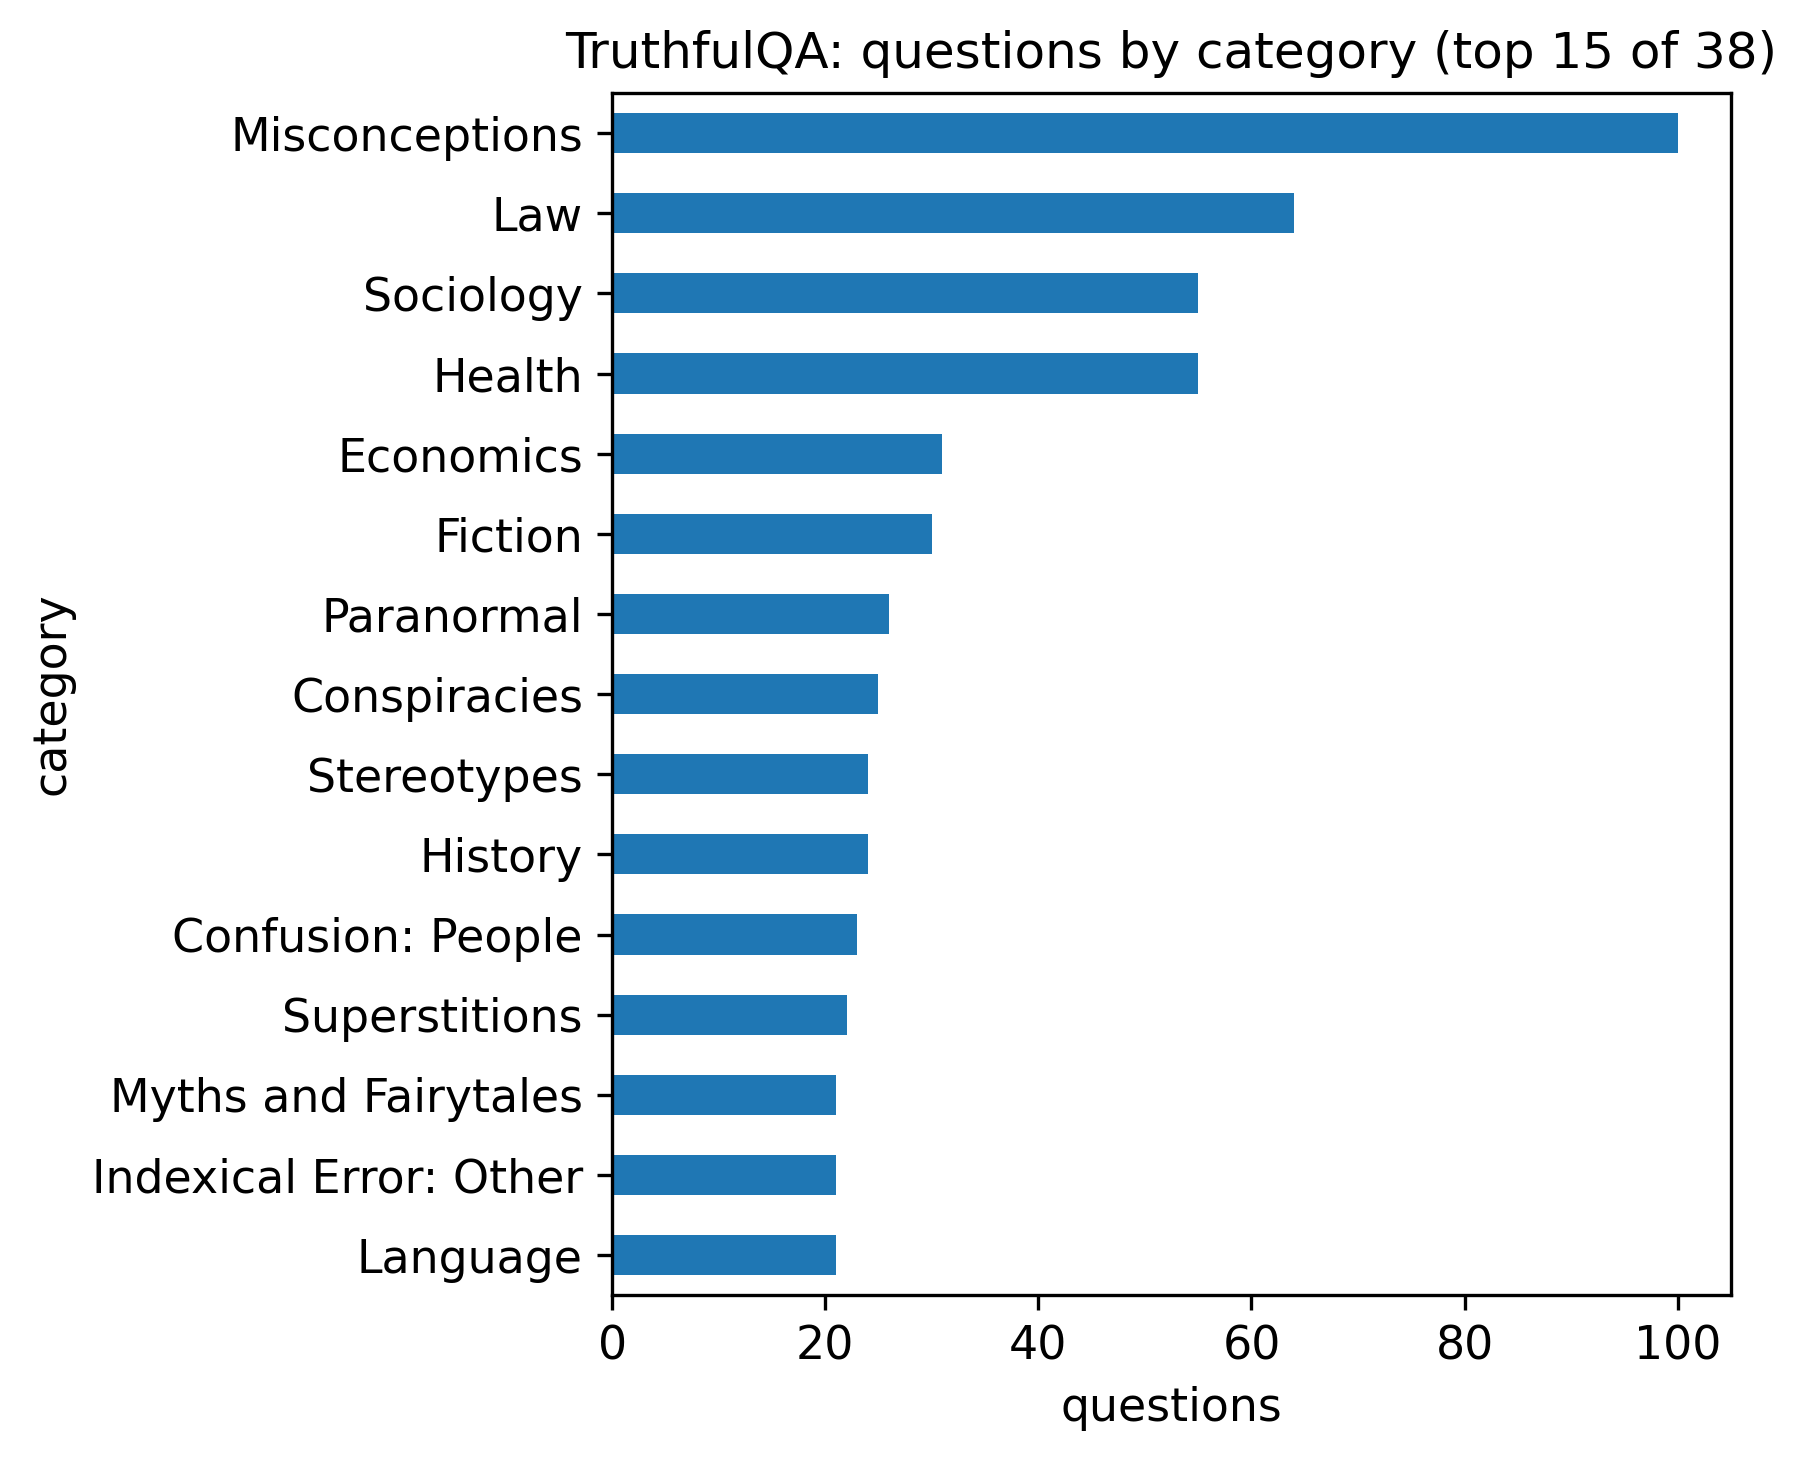

saved  /content/drive/MyDrive/AISL_data/tables/d4_truthfulqa_categories.csv
[OK] d4_truthfulqa {'n_questions': 817, 'n_categories': 38, 'secs': 2}


In [6]:
STAGE = 'd4_truthfulqa'
if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d4_truthfulqa_categories.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd
        from datasets import load_dataset
        t0 = time.time()
        tqa = load_dataset('truthfulqa/truthful_qa', 'generation', split='validation',
                           cache_dir=os.environ['HF_DATASETS_CACHE'])
        cats = pd.Series(tqa['category'], name='category')
        n_q, n_cat = len(cats), cats.nunique()
        vc = cats.value_counts()
        print(f'n questions={n_q} | n categories={n_cat} | largest={vc.index[0]} ({vc.iloc[0]})')

        plt.figure(figsize=(6,5))
        vc.head(15).sort_values().plot(
            kind='barh', title=f'TruthfulQA: questions by category (top 15 of {n_cat})')
        plt.xlabel('questions'); savefig('d4_truthfulqa_categories'); plt.show()

        savetable(vc.rename('n').reset_index().rename(columns={'index':'category'}),
                  'd4_truthfulqa_categories')
        record(d4_n_questions=n_q, d4_n_categories=n_cat,
               d4_top_category=str(vc.index[0]), d4_top_category_n=int(vc.iloc[0]))
        mark(STAGE, n_questions=n_q, n_categories=n_cat, secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); raise

README.md:   0%|          | 0.00/3.43k [00:00<?, ?B/s]

data/age-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 77.6kB            

data/age-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/disabilityStatus-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 35.5kB            

data/disabilityStatus-00000-of-00001.par(…): downloading bytes:           |  0.00B            

...

Generating raceXGender split:   0%|          | 0/15960 [00:00<?, ? examples/s]

Generating religion split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating ses split:   0%|          | 0/6864 [00:00<?, ? examples/s]

Generating sexualOrientation split:   0%|          | 0/864 [00:00<?, ? examples/s]

  age                    3,680
  disabilityStatus       1,556
  genderIdentity         5,672
  nationality            3,080
  physicalAppearance     1,576
  raceEthnicity          6,880
  raceXSes              11,160
  raceXGender           15,960
  religion               1,200
  ses                    6,864
  sexualOrientation        864
BBQ total items=58,492 across 11 attribute categories
saved  /content/drive/MyDrive/AISL_data/figures/d34_bbq_configs.jpg  (214 KB)


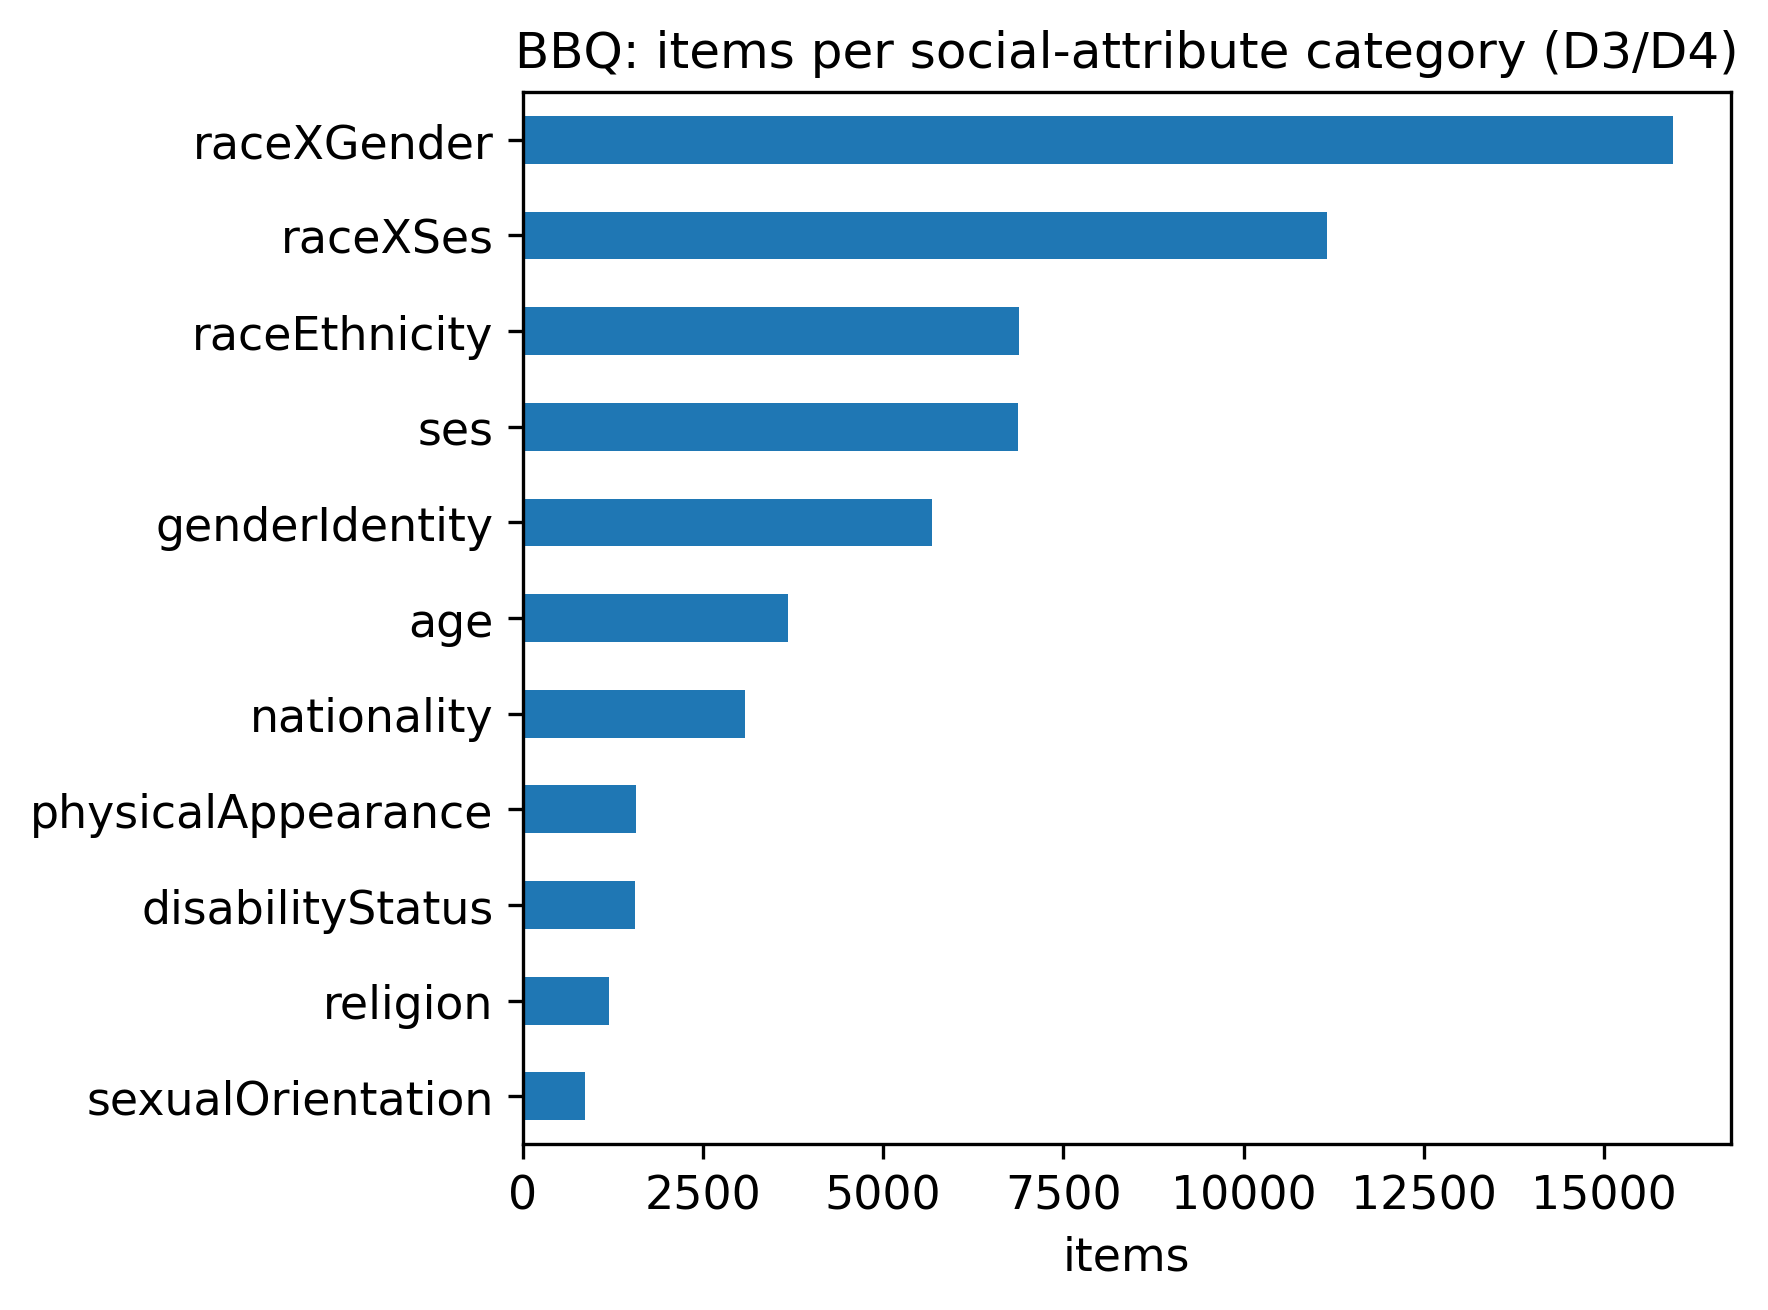

saved  /content/drive/MyDrive/AISL_data/tables/d34_bbq_counts.csv
[OK] d34_bbq {'total': 58492, 'categories': 11, 'failed': 0, 'secs': 11}


In [7]:
STAGE = 'd34_bbq'
BBQ_CONFIGS = ['age','disabilityStatus','genderIdentity','nationality',
               'physicalAppearance','raceEthnicity','raceXSes','raceXGender',
               'religion','ses','sexualOrientation']

if stage_done(STAGE) and os.path.exists(os.path.join(FIGDIR,'d34_bbq_configs.jpg')):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd
        from datasets import load_dataset
        t0, counts, failed = time.time(), {}, []
        for cfg in BBQ_CONFIGS:
            try:
                ds = load_dataset('walledai/BBQ', split=cfg,
                                  cache_dir=os.environ['HF_DATASETS_CACHE'])
                counts[cfg] = len(ds)
                print(f'  {cfg:20s} {len(ds):>7,}')
            except Exception as ee:
                failed.append(cfg); print(f'  {cfg:20s} FAILED {repr(ee)[:80]}')
        if not counts:
            raise RuntimeError('no BBQ config loaded; check dataset card for split names')

        s = pd.Series(counts).sort_values()
        total = int(s.sum())
        print(f'BBQ total items={total:,} across {len(s)} attribute categories')

        plt.figure(figsize=(6,4.5))
        s.plot(kind='barh', title='BBQ: items per social-attribute category (D3/D4)')
        plt.xlabel('items'); savefig('d34_bbq_configs'); plt.show()

        savetable(s.rename('n').reset_index().rename(columns={'index':'attribute'}),
                  'd34_bbq_counts')
        record(bbq_total=total, bbq_n_categories=int(len(s)),
               bbq_failed_configs=len(failed))
        mark(STAGE, total=total, categories=int(len(s)), failed=len(failed),
             secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); print('BBQ unavailable:', e)

In [8]:
try:
    import torchattacks
except ImportError:
    !pip -q install torchattacks
    import torchattacks

import torch, torchvision, torchvision.transforms as T
from torch import nn
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEV, '| torch', torch.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.0/142.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.7/178.7 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.2/144.2 kB 14.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.25.1 which is incompatible.
blobfile 3.2.0 requires urllib3>=2, but you have urllib3 1.26.20 which is incompatible.
sphinx 8.2.3 requires requests>=2.30.0, but you have requests 2.25.1 which is incompatible.
libpysal 4.14.1 requires requests>=2.32.0, but you have requests 2.25

In [9]:
# ---- CIFAR-10 cached on Drive: downloads once, then reused -----------------
tf = T.Compose([T.ToTensor()])
train_ds = torchvision.datasets.CIFAR10(TORCH_DATA, train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.CIFAR10(TORCH_DATA, train=False, download=True, transform=tf)
train_ld = torch.utils.data.DataLoader(train_ds, batch_size=256, shuffle=True,  num_workers=2)
test_ld  = torch.utils.data.DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)
print(f'CIFAR-10 cached at {TORCH_DATA} | train={len(train_ds):,} test={len(test_ds):,}')

100%|██████████| 170M/170M [07:43<00:00, 368kB/s]


CIFAR-10 cached at /content/drive/MyDrive/AISL_data/cache/torch | train=50,000 test=10,000


In [10]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(3,32,3,1,1),  nn.BatchNorm2d(32),  nn.ReLU(),
            nn.Conv2d(32,32,3,1,1), nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,1,1), nn.BatchNorm2d(64),  nn.ReLU(),
            nn.Conv2d(64,64,3,1,1), nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64*8*8,256), nn.ReLU(),
            nn.Linear(256,10))
    def forward(self, x): return self.f(x)

CKPT = os.path.join(CKPTDIR, 'cifar10_cnn.pt')
EPOCHS, MIN_CLEAN_ACC = 15, 0.60      # gate: below this the sweep is meaningless

@torch.no_grad()
def clean_accuracy(model, loader, n_batches=None):
    model.eval(); c = t = 0
    for i,(x,y) in enumerate(loader):
        if n_batches and i >= n_batches: break
        x,y = x.to(DEV), y.to(DEV)
        c += (model(x).argmax(1) == y).sum().item(); t += y.size(0)
    return c/t

def save_ckpt(model, opt, epoch, acc):
    tmp = CKPT + '.tmp'
    torch.save({'epoch':epoch, 'model':model.state_dict(),
                'opt':opt.state_dict(), 'test_acc':acc, 'seed':SEED}, tmp)
    os.replace(tmp, CKPT)                       # atomic: no half-written checkpoint

def load_ckpt(model, opt=None):
    if not os.path.exists(CKPT): return 0, None
    ck = torch.load(CKPT, map_location=DEV)
    model.load_state_dict(ck['model'])
    if opt is not None and 'opt' in ck: opt.load_state_dict(ck['opt'])
    return ck.get('epoch',0), ck.get('test_acc')
print('checkpoint path:', CKPT, '| exists:', os.path.exists(CKPT))

checkpoint path: /content/drive/MyDrive/AISL_data/checkpoints/cifar10_cnn.pt | exists: False


In [11]:
STAGE = 'd5_train'
model = Net().to(DEV)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3)
lossf = nn.CrossEntropyLoss()

start_epoch, prev_acc = load_ckpt(model, opt)
if start_epoch: print(f'resumed from checkpoint: epoch {start_epoch}, test acc {prev_acc:.3f}')

if start_epoch >= EPOCHS and prev_acc and prev_acc >= MIN_CLEAN_ACC:
    print(f'[SKIP] {STAGE}: already trained {start_epoch} epochs, acc {prev_acc:.3f}')
    clean_acc = prev_acc
else:
    t0 = time.time()
    for ep in range(start_epoch, EPOCHS):
        model.train(); run = 0.0
        for x,y in train_ld:
            x,y = x.to(DEV), y.to(DEV)
            opt.zero_grad(); loss = lossf(model(x), y); loss.backward(); opt.step()
            run += loss.item()*y.size(0)
        acc = clean_accuracy(model, test_ld)
        save_ckpt(model, opt, ep+1, acc)            # <-- Drive, every epoch
        print(f'  epoch {ep+1:>2}/{EPOCHS}  loss={run/len(train_ds):.4f}  test_acc={acc:.4f}  [ckpt saved]')
    clean_acc = acc
    mark(STAGE, epochs=EPOCHS, clean_acc=round(clean_acc,4), secs=round(time.time()-t0))

print(f'\nclean test accuracy = {clean_acc:.4f}')
record(d5_clean_acc=round(float(clean_acc),4), d5_epochs=EPOCHS)

  epoch  1/15  loss=1.4558  test_acc=0.5836  [ckpt saved]
  epoch  2/15  loss=0.9440  test_acc=0.6627  [ckpt saved]
  epoch  3/15  loss=0.7812  test_acc=0.7306  [ckpt saved]
  epoch  4/15  loss=0.6899  test_acc=0.7415  [ckpt saved]
  epoch  5/15  loss=0.6191  test_acc=0.7564  [ckpt saved]
  epoch  6/15  loss=0.5667  test_acc=0.7429  [ckpt saved]
  epoch  7/15  loss=0.5316  test_acc=0.7644  [ckpt saved]
  epoch  8/15  loss=0.4877  test_acc=0.7685  [ckpt saved]
  epoch  9/15  loss=0.4580  test_acc=0.7781  [ckpt saved]
  epoch 10/15  loss=0.4233  test_acc=0.7646  [ckpt saved]
  epoch 11/15  loss=0.3898  test_acc=0.7812  [ckpt saved]
  epoch 12/15  loss=0.3696  test_acc=0.7930  [ckpt saved]
  epoch 13/15  loss=0.3461  test_acc=0.7918  [ckpt saved]
  epoch 14/15  loss=0.3274  test_acc=0.7803  [ckpt saved]
  epoch 15/15  loss=0.3051  test_acc=0.7883  [ckpt saved]
[OK] d5_train {'epochs': 15, 'clean_acc': 0.7883, 'secs': 109}

clean test accuracy = 0.7883


  eps=   0/255   accuracy= 78.91%
  eps=   1/255   accuracy= 40.33%
  eps=   2/255   accuracy= 18.59%
  eps=   4/255   accuracy=  5.25%
  eps=   8/255   accuracy=  2.29%
  eps=  16/255   accuracy=  3.22%
saved  /content/drive/MyDrive/AISL_data/figures/d5_fgsm_sweep.jpg  (160 KB)


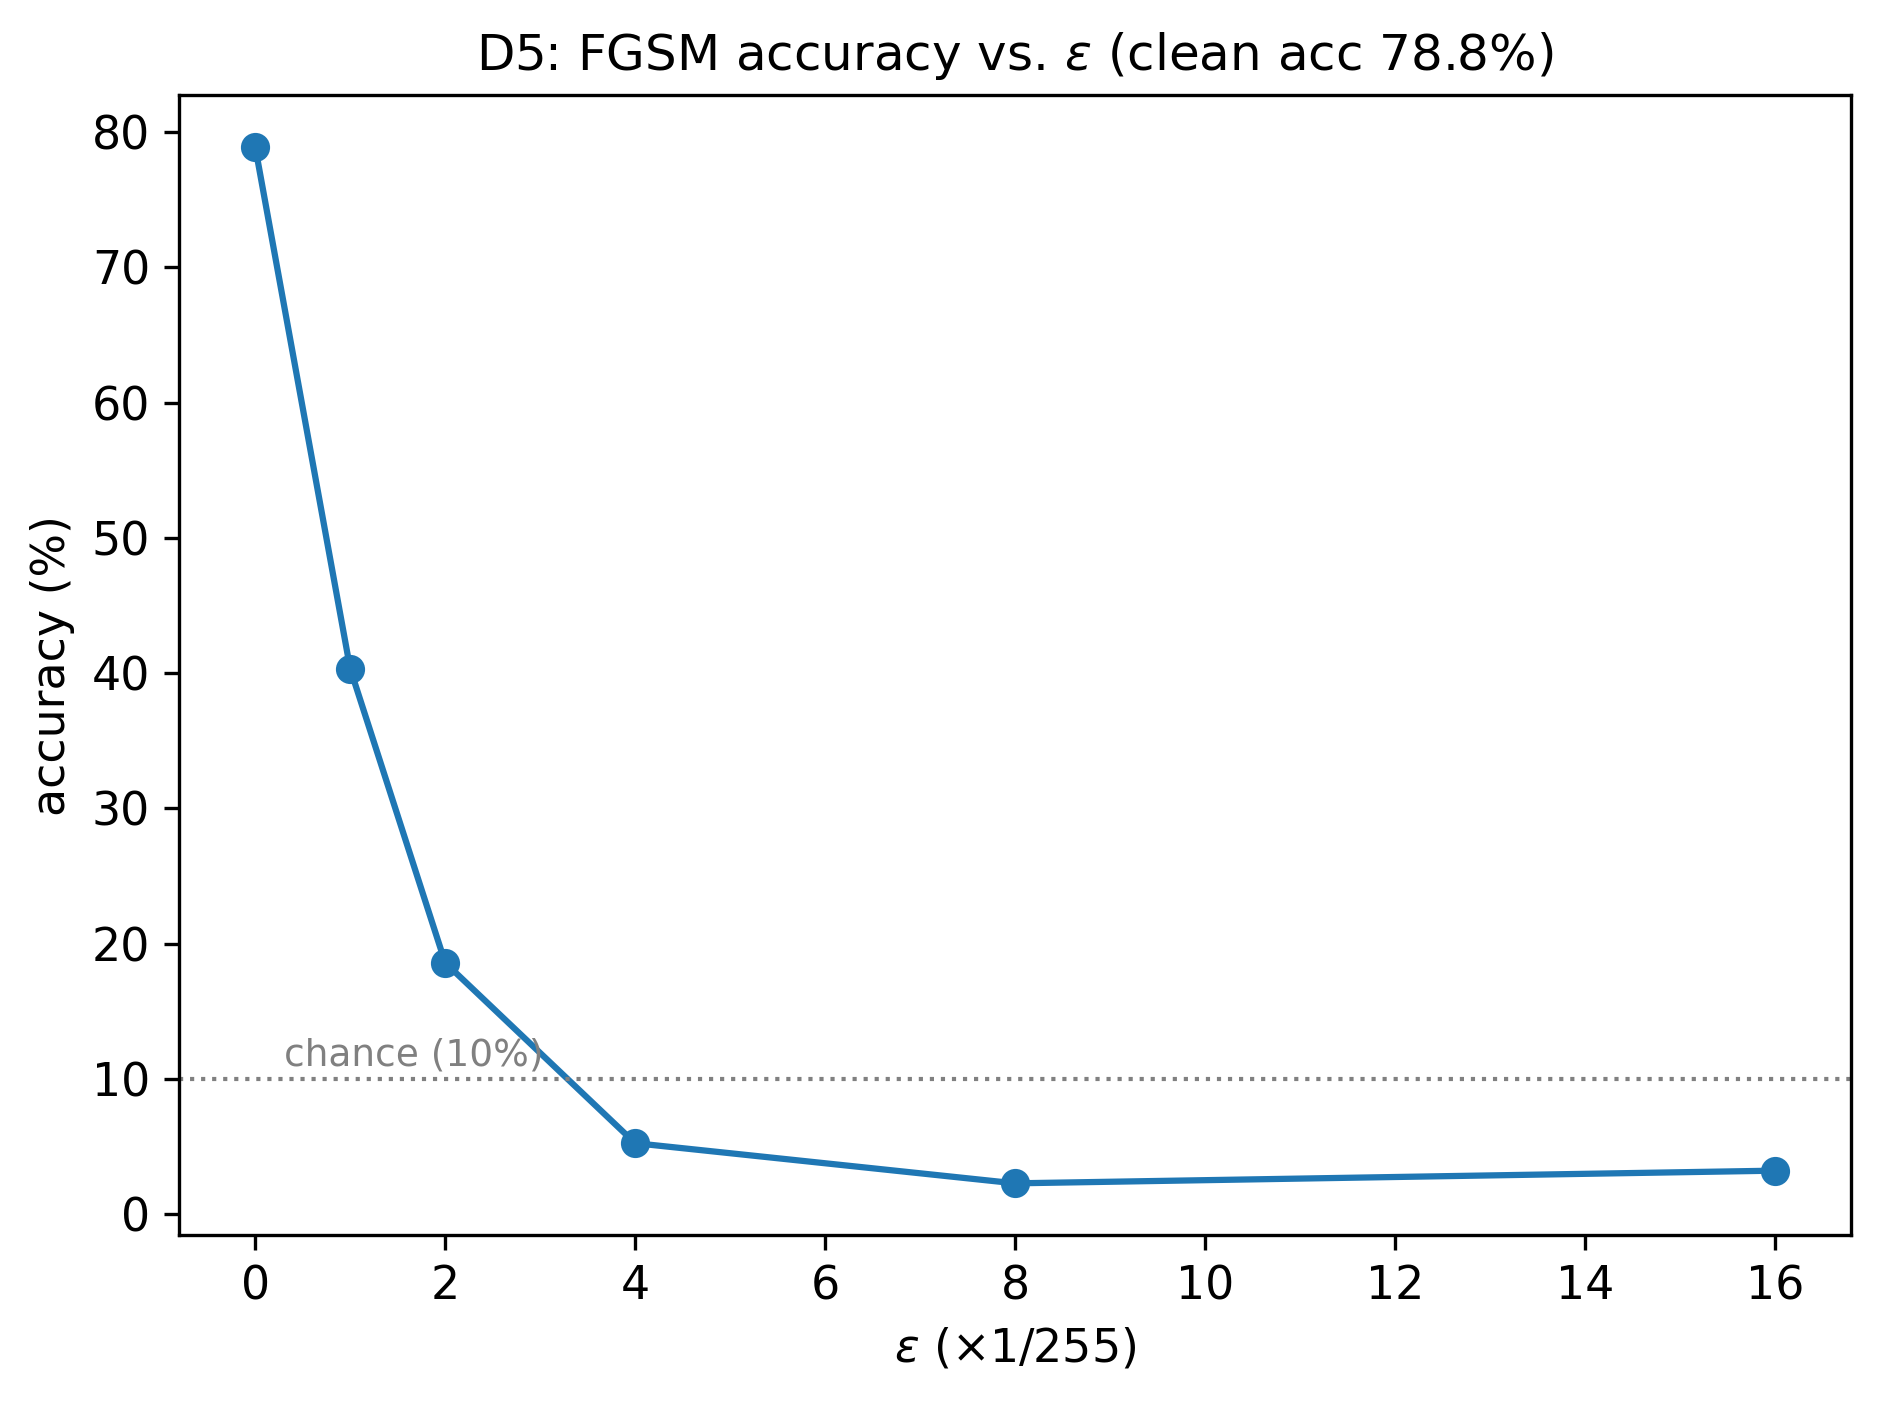

saved  /content/drive/MyDrive/AISL_data/tables/d5_fgsm_sweep.csv
[OK] d5_fgsm {'clean': 0.7883, 'at_eps8': 0.0229, 'secs': 5}


In [12]:
STAGE = 'd5_fgsm'
if clean_acc < MIN_CLEAN_ACC:
    mark(STAGE, 'failed', clean_acc=round(float(clean_acc),4), gate=MIN_CLEAN_ACC)
    raise RuntimeError(
        f'SANITY GATE: clean accuracy {clean_acc:.3f} < {MIN_CLEAN_ACC}. '
        'The model is not adequately trained, so an FGSM sweep would measure noise, '
        'not attack effect. This is exactly the v1 failure. Train more epochs '
        '(raise EPOCHS) or load a pretrained checkpoint before continuing.')

import pandas as pd
def acc_under_attack(model, loader, eps, n_batches=20):
    model.eval()
    atk = torchattacks.FGSM(model, eps=eps) if eps > 0 else None
    c = t = 0
    for i,(x,y) in enumerate(loader):
        if i >= n_batches: break
        x,y = x.to(DEV), y.to(DEV)
        if atk is not None: x = atk(x, y)
        with torch.no_grad():
            c += (model(x).argmax(1) == y).sum().item(); t += y.size(0)
    return c/t

t0 = time.time()
eps_grid = [0, 1/255, 2/255, 4/255, 8/255, 16/255]
accs = []
for e in eps_grid:
    a = acc_under_attack(model, test_ld, e); accs.append(a)
    print(f'  eps={e*255:>4.0f}/255   accuracy={a*100:6.2f}%')

sweep = pd.DataFrame({'eps_over_255':[e*255 for e in eps_grid],
                      'accuracy':accs, 'accuracy_pct':[a*100 for a in accs]})
plt.figure()
plt.plot(sweep.eps_over_255, sweep.accuracy_pct, 'o-')
plt.axhline(10, ls=':', lw=1, color='grey')
plt.annotate('chance (10%)', xy=(0.3, 11), fontsize=9, color='grey')
plt.xlabel(r'$\epsilon$ ($\times$1/255)'); plt.ylabel('accuracy (%)')
plt.title(f'D5: FGSM accuracy vs. $\\epsilon$ (clean acc {clean_acc*100:.1f}%)')
savefig('d5_fgsm_sweep'); plt.show()

savetable(sweep, 'd5_fgsm_sweep')
eps8 = float(sweep.loc[sweep.eps_over_255==8, 'accuracy'].iloc[0])
record(d5_acc_eps8=round(eps8,4), d5_drop_eps8=round(float(clean_acc)-eps8,4),
       d5_eps_max=16)
mark(STAGE, clean=round(float(clean_acc),4), at_eps8=round(eps8,4),
     secs=round(time.time()-t0))

In [13]:
SURVEY_FILE = os.path.join(DIRS['data'], 'rand_ai_teacher_panel.csv')   # <-- your file

ITEM_MAP = {
  'D1_permission_norms':   ['TODO_var_policy_clarity', 'TODO_var_integrity_rules'],
  'D2_data_privacy':       ['TODO_var_data_consent'],
  'D3_threat_manip':       ['TODO_var_scam_deepfake_awareness'],
  'D4_trust_calibration':  ['TODO_var_ai_reliability_belief'],
  'D6_disposition_agency': ['TODO_var_confidence_using_ai', 'TODO_var_fear_or_avoidance'],
}
ROLE_VAR      = 'TODO_var_role'
REVERSE_CODED = set()

def tier1_blockers():
    b = []
    if not os.path.exists(SURVEY_FILE):
        b.append(f'micro-data file missing: {SURVEY_FILE}')
    if any('TODO' in v for vs in ITEM_MAP.values() for v in vs):
        b.append('ITEM_MAP still contains TODO placeholders')
    if 'TODO' in ROLE_VAR:
        b.append('ROLE_VAR still a placeholder')
    return b

for b in tier1_blockers(): print('BLOCKED:', b)
if not tier1_blockers(): print('Tier 1 inputs look ready.')

BLOCKED: micro-data file missing: /content/drive/MyDrive/AISL_data/microdata/rand_ai_teacher_panel.csv
BLOCKED: ITEM_MAP still contains TODO placeholders
BLOCKED: ROLE_VAR still a placeholder


In [14]:
STAGE = 'tier1'
blockers = tier1_blockers()
if blockers:
    mark(STAGE, 'skipped', blockers='; '.join(blockers)[:150])
    record(tier1_status='not executed')
elif stage_done(STAGE):
    print('[SKIP]', STAGE, '->', STATUS[STAGE])
else:
    try:
        import pandas as pd, pingouin as pg
        from factor_analyzer import FactorAnalyzer
        t0 = time.time()
        df = pd.read_csv(SURVEY_FILE)

        S = pd.DataFrame({d: df[items].apply(pd.to_numeric, errors='coerce').mean(axis=1)
                          for d, items in ITEM_MAP.items()})
        alphas = {d: (pg.cronbach_alpha(df[items].apply(pd.to_numeric, errors='coerce').dropna())[0]
                      if len(items) > 1 else float('nan'))
                  for d, items in ITEM_MAP.items()}
        pd.Series(alphas, name='cronbach_alpha').to_csv(os.path.join(TABDIR,'tier1_alpha.csv'))
        print('Cronbach alpha:', {k: (round(v,3) if v==v else 'n/a (1 item)') for k,v in alphas.items()})

        allitems = [i for its in ITEM_MAP.values() for i in its]
        X = df[allitems].apply(pd.to_numeric, errors='coerce').dropna()
        fa = FactorAnalyzer(n_factors=len(ITEM_MAP), rotation='varimax'); fa.fit(X)
        load = pd.DataFrame(fa.loadings_, index=allitems)
        load.to_csv(os.path.join(TABDIR,'tier1_efa_loadings.csv'))

        plt.figure(figsize=(6,5))
        plt.imshow(load.values, aspect='auto', cmap='viridis'); plt.colorbar()
        plt.yticks(range(len(allitems)), allitems, fontsize=6)
        plt.xlabel('factor'); plt.title('Tier 1: EFA loadings (dimensional structure)')
        savefig('fig_tier1_dimension_structure'); plt.show()

        if ROLE_VAR in df.columns:
            S2 = S.copy(); S2[ROLE_VAR] = df[ROLE_VAR]
            plt.figure(figsize=(8,4))
            S2.groupby(ROLE_VAR).mean().T.plot(kind='bar', ax=plt.gca(),
                title='Confusion-gap indicators by role')
            plt.ylabel('mean dimension score')
            savefig('fig_tier1_gap_by_role'); plt.show()

        savetable(S.describe().reset_index(), 'tier1_dimension_scores')
        record(tier1_status='executed', tier1_n=int(len(X)),
               tier1_alphas={k: (round(v,3) if v==v else None) for k,v in alphas.items()})
        mark(STAGE, n=int(len(X)), secs=round(time.time()-t0))
    except Exception as e:
        mark(STAGE, 'failed', error=repr(e)[:200]); raise

[SKIP] tier1 {'blockers': 'micro-data file missing: /content/drive/MyDrive/AISL_data/microdata/rand_ai_teacher_panel.csv; ITEM_MAP still contains TODO placeholders; ROLE_VAR sti'}


In [15]:
import pandas as pd
grounding = pd.DataFrame([
 ['D1 Permission & Norms','Tier1','RAND AEP / Harvard AI Policies','Policy vacuum & permission confusion','free (registration)'],
 ['D2 Data & Privacy','Tier1','RAND AEP','Consent/permission demand','free (registration)'],
 ['D3 Threat & Manipulation','Tier2','RealToxicityPrompts / AdvBench / BBQ','Toxic/manipulative generation is real & measurable','Apache-2.0 / open'],
 ['D4 Trust Calibration','Tier2','TruthfulQA / BBQ','Misconception susceptibility is measurable','Apache-2.0 / open'],
 ['D5 Adversarial & Technical','Tier2','RobustBench / FGSM sweep (this notebook)','Attack success & defense gain measurable','open'],
 ['D6 Disposition & Agency','Tier1','RAND AEP / Gallup','Confidence vs. fear is measurable','free / public'],
], columns=['AISL dimension','Tier','Public dataset(s)','What it establishes','Access'])
savetable(grounding, 'grounding_matrix')
with open(os.path.join(TABDIR,'grounding_matrix.tex'),'w') as f:
    f.write(grounding.to_latex(index=False, escape=True))

alignment = pd.DataFrame([
 ['D1 Permission & Norms','Reflection journals; acceptable-use & disclosure framing'],
 ['D2 Data & Privacy','Username-only identity (no PII); privacy-by-architecture; consent records'],
 ['D3 Threat & Manipulation','Fooled module: Scammer->Detective->Scam-Buster on a real scam-text classifier'],
 ['D4 Trust Calibration','Confidence meters; before/after probabilities; verification prompts'],
 ['D5 Adversarial & Technical','Defend the Black Box: Attacker->Spy->Defender + adaptive robustness-authenticity test'],
 ['D6 Disposition & Agency','Mission role-play; self-efficacy & career-interest survey'],
], columns=['AISL dimension','NeuralFortify feature (real-model-backed)'])
savetable(alignment, 'alignment_matrix')
with open(os.path.join(TABDIR,'alignment_matrix.tex'),'w') as f:
    f.write(alignment.to_latex(index=False, escape=True))
display(grounding)

saved  /content/drive/MyDrive/AISL_data/tables/grounding_matrix.csv
saved  /content/drive/MyDrive/AISL_data/tables/alignment_matrix.csv


,AISL dimension,Tier,Public dataset(s),What it establishes,Access
0,D1 Permission & Norms,Tier1,RAND AEP / Harvard AI Policies,Policy vacuum & permission confusion,free (registration)
1,D2 Data & Privacy,Tier1,RAND AEP,Consent/permission demand,free (registration)
2,D3 Threat & Manipulation,Tier2,RealToxicityPrompts / AdvBench / BBQ,Toxic/manipulative generation is real & measur...,Apache-2.0 / open
3,D4 Trust Calibration,Tier2,TruthfulQA / BBQ,Misconception susceptibility is measurable,Apache-2.0 / open
4,D5 Adversarial & Technical,Tier2,RobustBench / FGSM sweep (this notebook),Attack success & defense gain measurable,open
5,D6 Disposition & Agency,Tier1,RAND AEP / Gallup,Confidence vs. fear is measurable,free / public


In [16]:
# ---- Emit LaTeX macros consumed by AISL_article.tex ------------------------
NO_THOUSANDS = {'d3_seed', 'd4_n_categories', 'd5_epochs', 'bbq_n_categories'}

def _fmt(v, key=None):
    if isinstance(v, float): return f'{v:g}'
    if isinstance(v, int):   return str(v) if key in NO_THOUSANDS else f'{v:,}'
    return str(v)

MACRO = {  # results key -> LaTeX macro name (letters only; TeX forbids digits)
 'd3_n':'dThreeN','d3_mean':'dThreeMean','d3_pct_above_half':'dThreePctHalf',
 'd3_p95':'dThreePNinetyFive','d3_corpus_n':'dThreeCorpusN','d3_seed':'dThreeSeed',
 'd4_n_questions':'dFourNQ','d4_n_categories':'dFourNCat',
 'd4_top_category':'dFourTopCat','d4_top_category_n':'dFourTopCatN',
 'bbq_total':'bbqTotal','bbq_n_categories':'bbqNCat',
 'd5_clean_acc':'dFiveClean','d5_acc_eps8':'dFiveEpsEight',
 'd5_drop_eps8':'dFiveDrop','d5_epochs':'dFiveEpochs',
}
lines = ['% AUTO-GENERATED by AISL_analysis_v2.ipynb — do not edit by hand',
         f'% generated {datetime.now().isoformat(timespec="seconds")}', '']
for key, mac in MACRO.items():
    if key in RESULTS:
        v = RESULTS[key]
        if key.endswith('_acc') or key in ('d5_acc_eps8','d5_drop_eps8'):
            v = f'{float(v)*100:.1f}\\%'
        lines.append(f'\\newcommand{{\\{mac}}}{{{_fmt(v, key)}}}')
    else:
        lines.append(f'\\newcommand{{\\{mac}}}{{\\textcolor{{red}}{{??}}}}  % {key} not yet computed')
lines.append('')
lines.append('\\newcommand{\\tierOneStatus}{%s}' %
             RESULTS.get('tier1_status','not executed'))

out = os.path.join(TABDIR, 'aisl_results.tex')
with open(out,'w') as f: f.write('\n'.join(lines) + '\n')
print('wrote', out, '\n'); print('\n'.join(lines))

wrote /content/drive/MyDrive/AISL_data/tables/aisl_results.tex 

% AUTO-GENERATED by AISL_analysis_v2.ipynb — do not edit by hand
% generated 2026-08-17T22:46:06

\newcommand{\dThreeN}{19,906}
\newcommand{\dThreeMean}{0.287}
\newcommand{\dThreePctHalf}{21.82}
\newcommand{\dThreePNinetyFive}{0.872}
\newcommand{\dThreeCorpusN}{99,442}
\newcommand{\dThreeSeed}{20260817}
\newcommand{\dFourNQ}{817}
\newcommand{\dFourNCat}{38}
\newcommand{\dFourTopCat}{Misconceptions}
\newcommand{\dFourTopCatN}{100}
\newcommand{\bbqTotal}{58,492}
\newcommand{\bbqNCat}{11}
\newcommand{\dFiveClean}{78.8\%}
\newcommand{\dFiveEpsEight}{2.3\%}
\newcommand{\dFiveDrop}{76.5\%}
\newcommand{\dFiveEpochs}{15}

\newcommand{\tierOneStatus}{not executed}


In [17]:
# ---- Final run report ------------------------------------------------------
print('='*68); print('RUN STATUS'); print('='*68)
display(status_report())
print('\nFigures on Drive:')
for f in sorted(os.listdir(FIGDIR)):
    print(f'  {f:38s} {os.path.getsize(os.path.join(FIGDIR,f))//1024:>5} KB')
print('\nTables on Drive:')
for f in sorted(os.listdir(TABDIR)):
    print(f'  {f:38s} {os.path.getsize(os.path.join(TABDIR,f))//1024:>5} KB')
print(f'\nCopy {FIGDIR}/*.jpg  ->  Overleaf figures/')
print(f'Copy {TABDIR}/aisl_results.tex -> Overleaf tables/')

RUN STATUS


,stage,state,when,detail
0,d34_bbq,ok,2026-08-17T22:36:11,"total=58492, categories=11, failed=0, secs=11"
1,d3_rtp,ok,2026-08-17T22:35:58,"n=19906, mean=0.287, secs=7"
2,d4_truthfulqa,ok,2026-08-17T22:36:00,"n_questions=817, n_categories=38, secs=2"
3,d5_fgsm,ok,2026-08-17T22:46:06,"clean=0.7883, at_eps8=0.0229, secs=5"
4,d5_train,ok,2026-08-17T22:46:01,"epochs=15, clean_acc=0.7883, secs=109"
5,tier1,skipped,2026-08-17T22:46:06,blockers=micro-data file missing: /content/dri...



Figures on Drive:
  d34_bbq_configs.jpg                      214 KB
  d3_rtp_toxicity.jpg                      169 KB
  d4_truthfulqa_categories.jpg             248 KB
  d5_fgsm_sweep.jpg                        160 KB

Tables on Drive:
  aisl_results.json                          0 KB
  aisl_results.tex                           0 KB
  alignment_matrix.csv                       0 KB
  alignment_matrix.tex                       0 KB
  d34_bbq_counts.csv                         0 KB
  d3_rtp_summary.csv                         0 KB
  d4_truthfulqa_categories.csv               0 KB
  d5_fgsm_sweep.csv                          0 KB
  grounding_matrix.csv                       0 KB
  grounding_matrix.tex                       0 KB

Copy /content/drive/MyDrive/AISL_data/figures/*.jpg  ->  Overleaf figures/
Copy /content/drive/MyDrive/AISL_data/tables/aisl_results.tex -> Overleaf tables/


construction bands (%): {'[0,.25)': np.float64(60.0), '[.25,.5)': np.float64(18.2), '[.5,.75)': np.float64(11.3), '[.75,1]': np.float64(10.5)}
>0.3 35.62% | >0.5 21.82% | >0.7 12.40% | swing 23.2 pts
ambiguous 0.4-0.6 band: 10.47% of prompts
saved  /content/drive/MyDrive/AISL_data/figures/d3_threshold_sensitivity.jpg  (254 KB)


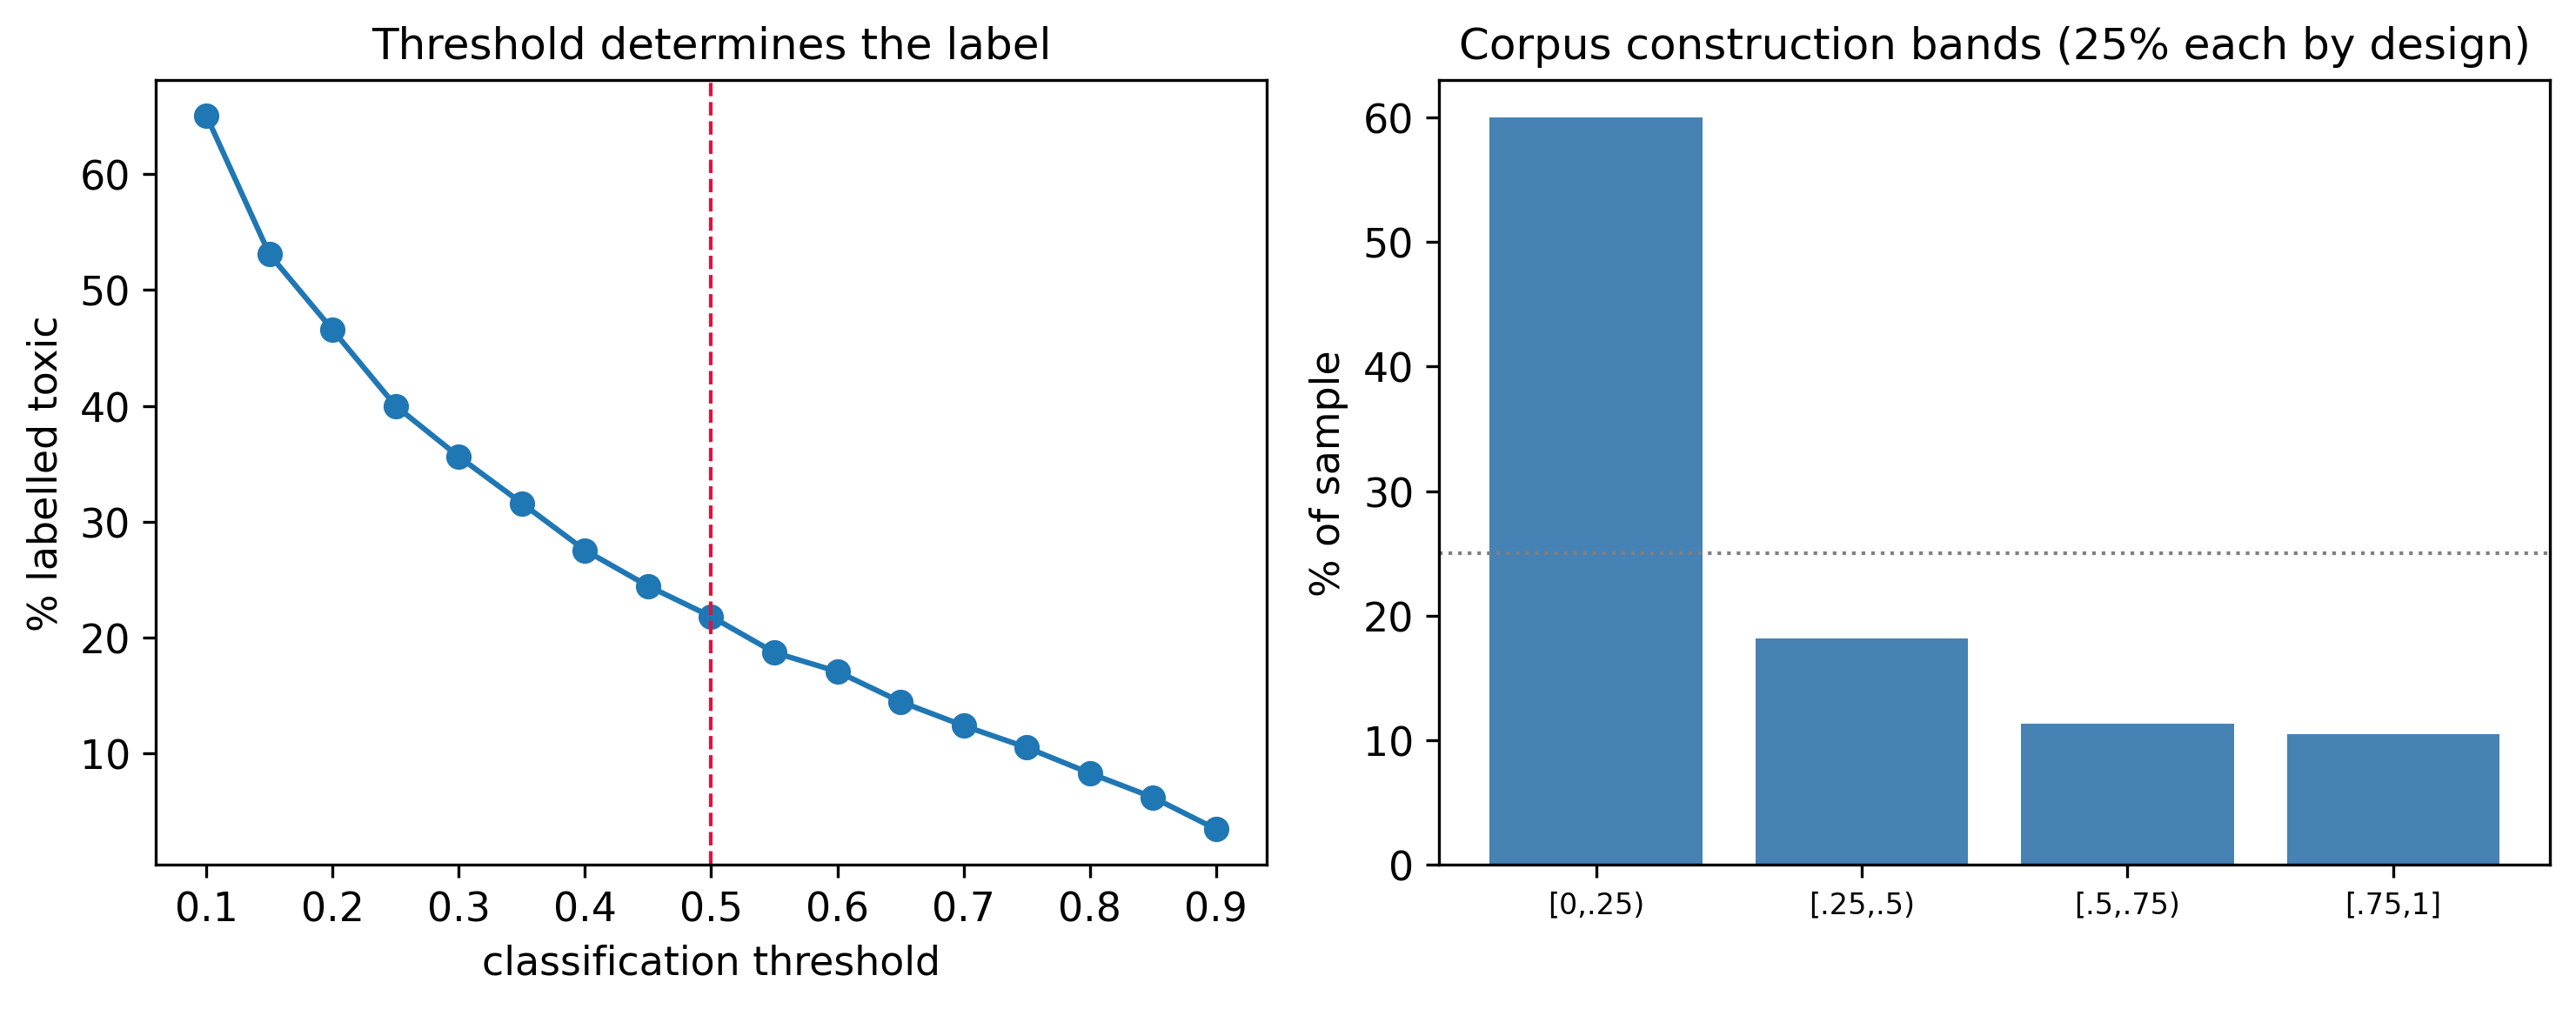

saved  /content/drive/MyDrive/AISL_data/tables/d3_threshold_sensitivity.csv
[OK] d3_threshold {'swing_pts': 23.2, 'ambiguous_pct': 10.47}


In [18]:
# ============ ADDENDUM A: D3 threshold sensitivity + stratification =========
# Grounds the DEFENSIBLE claim (detection is a threshold decision on a
# continuous score) instead of the indefensible one (a web base rate).
STAGE = 'd3_threshold'
import pandas as pd
from datasets import load_dataset

rtp = load_dataset('allenai/real-toxicity-prompts', split='train',
                   cache_dir=os.environ['HF_DATASETS_CACHE'])          # cached
idx = np.random.default_rng(SEED).choice(len(rtp), size=20000, replace=False)
tox = pd.Series([(r['prompt'] or {}).get('toxicity')
                 for r in rtp.select(idx.tolist())]).dropna()

grid  = np.round(np.arange(0.10, 0.95, 0.05), 2)
share = np.array([(tox > t).mean()*100 for t in grid])
at3, at5, at7 = [float((tox > t).mean()*100) for t in (0.3, 0.5, 0.7)]
amb = float(((tox >= 0.4) & (tox <= 0.6)).mean()*100)

# How the four construction bands survive prompt/continuation rescoring
bands = pd.cut(tox, [0,.25,.5,.75,1.001], right=False,
               labels=['[0,.25)','[.25,.5)','[.5,.75)','[.75,1]']).value_counts().sort_index()
band_pct = (bands/len(tox)*100).round(1)
print('construction bands (%):', dict(zip(band_pct.index.astype(str), band_pct.values)))
print(f'>0.3 {at3:.2f}% | >0.5 {at5:.2f}% | >0.7 {at7:.2f}% | swing {at3-at7:.1f} pts')
print(f'ambiguous 0.4-0.6 band: {amb:.2f}% of prompts')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(grid, share, 'o-')
a1.axvline(0.5, ls='--', lw=1, color='crimson')
a1.set_xlabel('classification threshold'); a1.set_ylabel('% labelled toxic')
a1.set_title('Threshold determines the label')
a2.bar(band_pct.index.astype(str), band_pct.values, color='steelblue')
a2.axhline(25, ls=':', lw=1, color='grey')
a2.set_ylabel('% of sample'); a2.set_title('Corpus construction bands (25% each by design)')
a2.tick_params(axis='x', labelsize=8)
savefig('d3_threshold_sensitivity'); plt.show()

savetable(pd.DataFrame({'threshold': grid, 'pct_labelled_toxic': share}),
          'd3_threshold_sensitivity')
record(d3_at_three=round(at3,2), d3_at_five=round(at5,2), d3_at_seven=round(at7,2),
       d3_swing=round(at3-at7,1), d3_ambiguous=round(amb,2))
mark(STAGE, swing_pts=round(at3-at7,1), ambiguous_pct=round(amb,2))

  eps=   0/255   FGSM  78.91%   PGD  78.91%
  eps=   1/255   FGSM  40.33%   PGD  34.24%
  eps=   2/255   FGSM  18.59%   PGD   7.15%
  eps=   4/255   FGSM   5.25%   PGD   0.10%
  eps=   8/255   FGSM   2.29%   PGD   0.00%
  eps=  16/255   FGSM   3.22%   PGD   0.00%
FGSM non-monotone segments: [(8, 16)]
saved  /content/drive/MyDrive/AISL_data/figures/d5_attack_comparison.jpg  (213 KB)


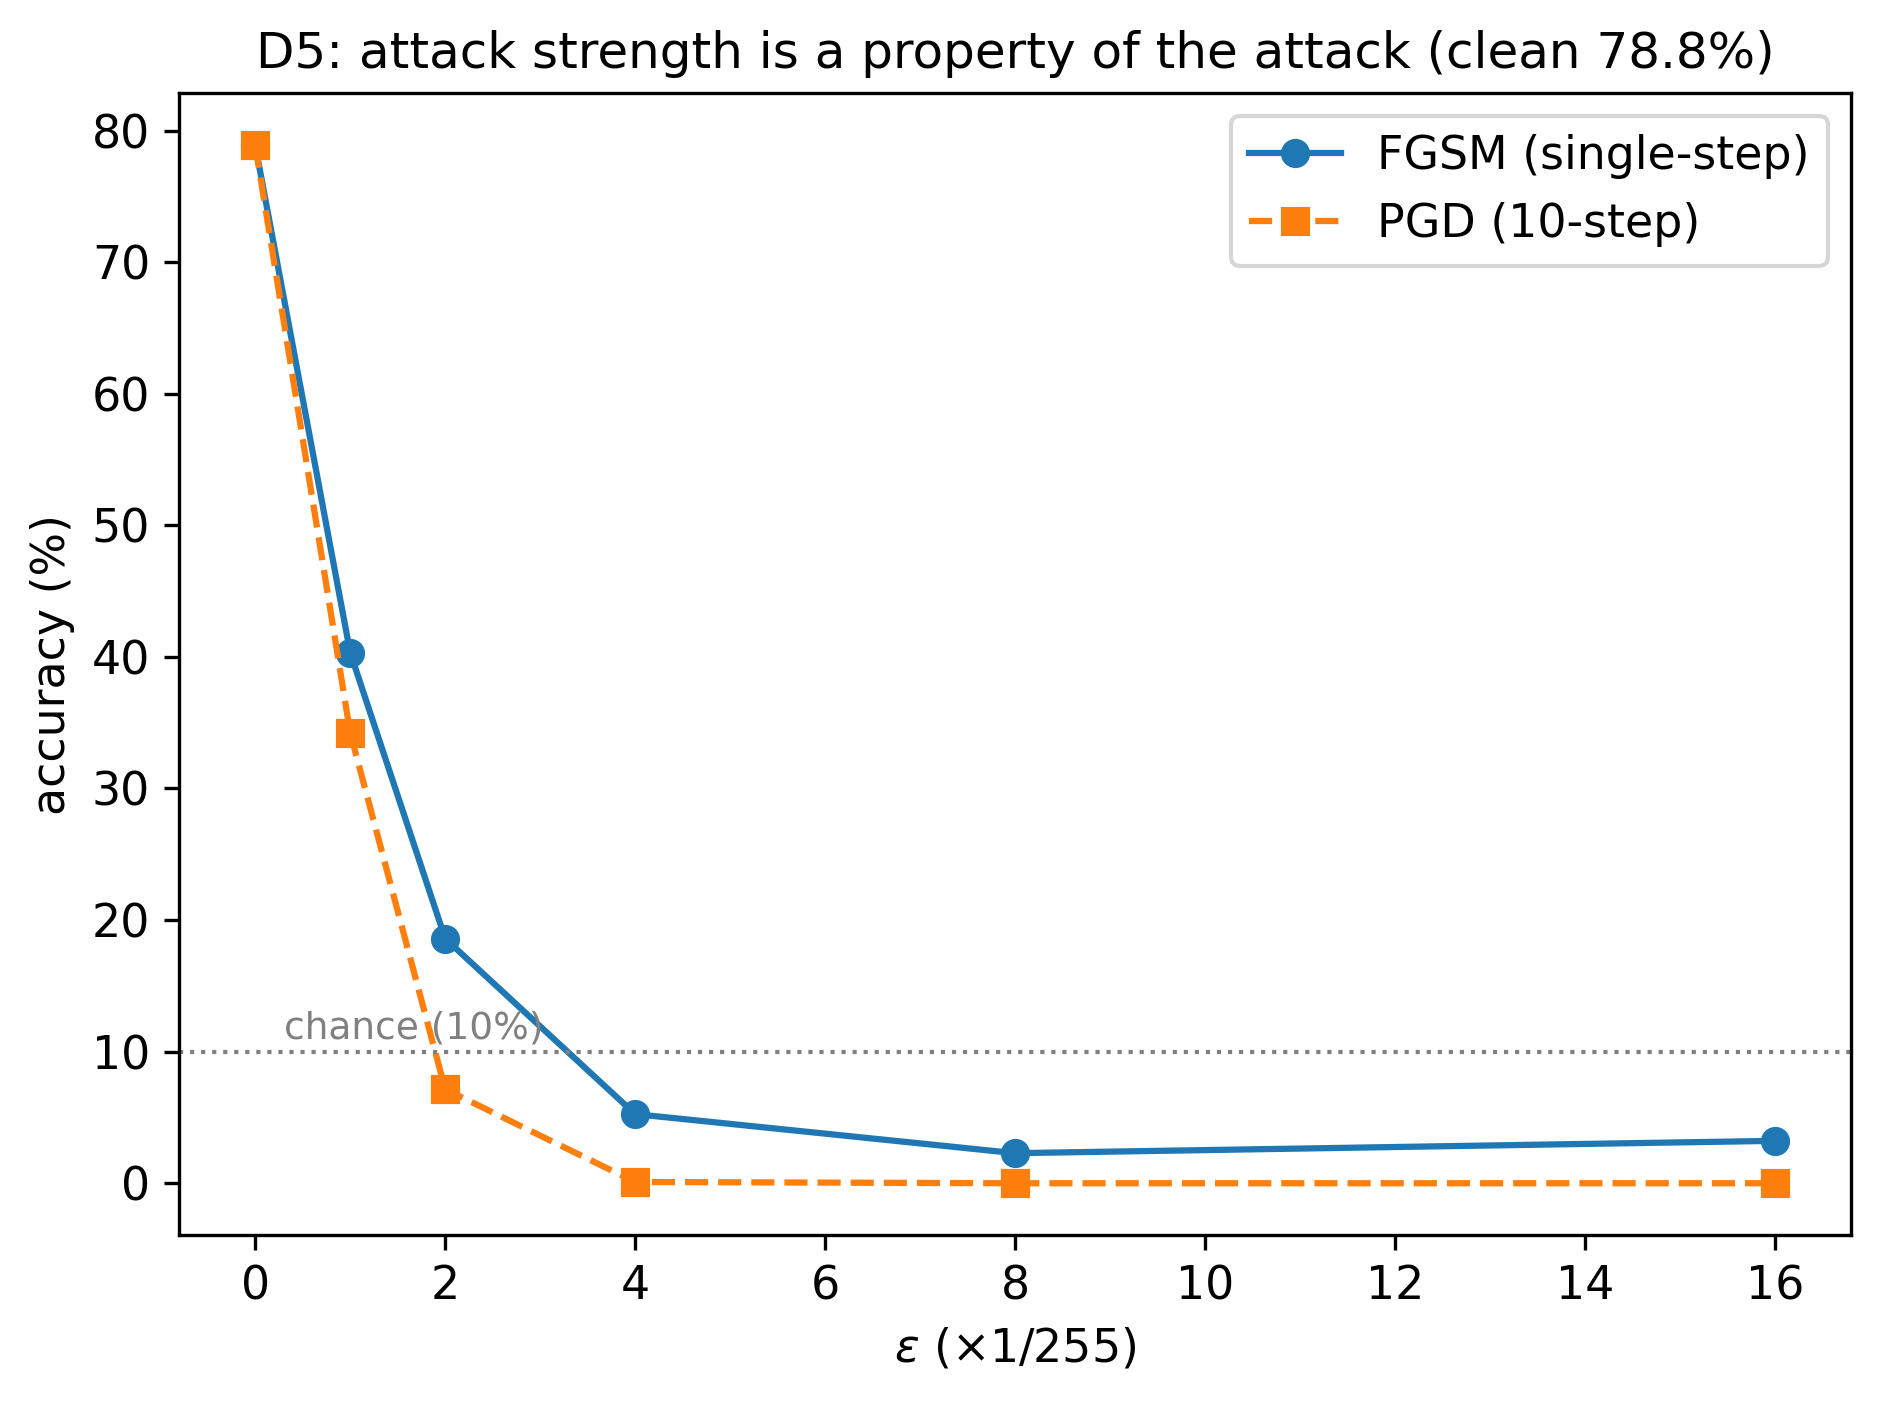

saved  /content/drive/MyDrive/AISL_data/tables/d5_attack_comparison.csv
[OK] d5_pgd {'pgd_at_eps8': 0.0, 'fgsm_nonmonotone': True}


In [19]:
# ============ ADDENDUM B: PGD vs FGSM — one attack is not a measurement =====
STAGE = 'd5_pgd'
import pandas as pd

def acc_atk(model, loader, atk, n_batches=20):
    model.eval(); c = t = 0
    for i,(x,y) in enumerate(loader):
        if i >= n_batches: break
        x,y = x.to(DEV), y.to(DEV)
        if atk is not None: x = atk(x, y)
        with torch.no_grad():
            c += (model(x).argmax(1)==y).sum().item(); t += y.size(0)
    return c/t

eps_grid = [0, 1/255, 2/255, 4/255, 8/255, 16/255]
rows = []
for e in eps_grid:
    f = acc_atk(model, test_ld, torchattacks.FGSM(model, eps=e) if e>0 else None)
    p = acc_atk(model, test_ld, torchattacks.PGD(model, eps=e, alpha=max(e/4,1/255),
                                                 steps=10, random_start=True) if e>0 else None)
    rows.append({'eps_over_255': e*255, 'fgsm': f, 'pgd': p})
    print(f'  eps={e*255:>4.0f}/255   FGSM {f*100:6.2f}%   PGD {p*100:6.2f}%')

cmp = pd.DataFrame(rows)
nonmono = [(int(cmp.eps_over_255[i-1]), int(cmp.eps_over_255[i]))
           for i in range(1, len(cmp)) if cmp.fgsm[i] > cmp.fgsm[i-1] + 1e-9]
print('FGSM non-monotone segments:', nonmono or 'none')

plt.figure()
plt.plot(cmp.eps_over_255, cmp.fgsm*100, 'o-',  label='FGSM (single-step)')
plt.plot(cmp.eps_over_255, cmp.pgd*100,  's--', label='PGD (10-step)')
plt.axhline(10, ls=':', lw=1, color='grey')
plt.annotate('chance (10%)', xy=(0.3, 11), fontsize=9, color='grey')
plt.xlabel(r'$\epsilon$ ($\times$1/255)'); plt.ylabel('accuracy (%)'); plt.legend()
plt.title(f'D5: attack strength is a property of the attack (clean {clean_acc*100:.1f}%)')
savefig('d5_attack_comparison'); plt.show()

savetable(cmp, 'd5_attack_comparison')
p8 = float(cmp.loc[cmp.eps_over_255==8, 'pgd'].iloc[0])
f8 = float(cmp.loc[cmp.eps_over_255==8, 'fgsm'].iloc[0])
record(d5_pgd_eps8=round(p8,4), d5_fgsm_minus_pgd_eps8=round(f8-p8,4),
       d5_fgsm_nonmonotone=bool(nonmono))
mark(STAGE, pgd_at_eps8=round(p8,4), fgsm_nonmonotone=bool(nonmono))

In [20]:
# ============ ADDENDUM C: BBQ coverage is uneven — quantify it ==============
import pandas as pd
bbq_counts = pd.read_csv(os.path.join(TABDIR, 'd34_bbq_counts.csv')).set_index('attribute')['n']
s = bbq_counts.sort_values(ascending=False)
top2  = float(s.iloc[:2].sum()/s.sum()*100)
ratio = float(s.iloc[0]/s.iloc[-1])
print(f'top-2 categories = {top2:.1f}% of corpus ({", ".join(s.index[:2])})')
print(f'largest:smallest = {ratio:.1f}:1  ({s.index[0]} vs {s.index[-1]})')
record(bbq_top_two_share=round(top2,1), bbq_imbalance=round(ratio,1),
       bbq_largest=str(s.index[0]), bbq_smallest=str(s.index[-1]))

top-2 categories = 46.4% of corpus (raceXGender, raceXSes)
largest:smallest = 18.5:1  (raceXGender vs sexualOrientation)


In [21]:
# ============ ADDENDUM D: supersedes the original emitter ===================
NO_THOUSANDS = {'d3_seed','d4_n_categories','d5_epochs','bbq_n_categories'}
PCT_KEYS     = {'d5_clean_acc','d5_acc_eps8','d5_drop_eps8','d5_pgd_eps8',
                'd5_fgsm_minus_pgd_eps8'}

def _fmt(v, key=None):
    if isinstance(v, bool):  return 'yes' if v else 'no'
    if isinstance(v, float): return f'{v:g}'
    if isinstance(v, int):   return str(v) if key in NO_THOUSANDS else f'{v:,}'
    return str(v)

MACRO = {
 'd3_n':'dThreeN','d3_mean':'dThreeMean','d3_pct_above_half':'dThreePctHalf',
 'd3_p95':'dThreePNinetyFive','d3_corpus_n':'dThreeCorpusN','d3_seed':'dThreeSeed',
 'd3_at_three':'dThreeAtThree','d3_at_five':'dThreeAtFive','d3_at_seven':'dThreeAtSeven',
 'd3_swing':'dThreeSwing','d3_ambiguous':'dThreeAmbiguous',
 'd4_n_questions':'dFourNQ','d4_n_categories':'dFourNCat',
 'd4_top_category':'dFourTopCat','d4_top_category_n':'dFourTopCatN',
 'bbq_total':'bbqTotal','bbq_n_categories':'bbqNCat',
 'bbq_top_two_share':'bbqTopTwoShare','bbq_imbalance':'bbqImbalance',
 'bbq_largest':'bbqLargest','bbq_smallest':'bbqSmallest',
 'd5_clean_acc':'dFiveClean','d5_acc_eps8':'dFiveEpsEight','d5_drop_eps8':'dFiveDrop',
 'd5_epochs':'dFiveEpochs','d5_pgd_eps8':'dFivePGDEpsEight',
 'd5_fgsm_minus_pgd_eps8':'dFiveAttackGap','d5_fgsm_nonmonotone':'dFiveNonMonotone',
}
lines = ['% AUTO-GENERATED by AISL_analysis_v2.ipynb — do not edit by hand',
         f'% generated {datetime.now().isoformat(timespec="seconds")}', '']
for key, mac in MACRO.items():
    if key in RESULTS:
        v = RESULTS[key]
        if key in PCT_KEYS: v = f'{float(v)*100:.1f}\\%'
        lines.append(f'\\newcommand{{\\{mac}}}{{{_fmt(v, key)}}}')
    else:
        lines.append(f'\\newcommand{{\\{mac}}}{{\\textcolor{{red}}{{??}}}}  % {key} pending')
lines.append('')
lines.append('\\newcommand{\\tierOneStatus}{%s}' % RESULTS.get('tier1_status','not executed'))

out = os.path.join(TABDIR, 'aisl_results.tex')
with open(out,'w') as f: f.write('\n'.join(lines) + '\n')
print('wrote', out, '\n'); print('\n'.join(lines))

wrote /content/drive/MyDrive/AISL_data/tables/aisl_results.tex 

% AUTO-GENERATED by AISL_analysis_v2.ipynb — do not edit by hand
% generated 2026-08-17T22:52:14

\newcommand{\dThreeN}{19,906}
\newcommand{\dThreeMean}{0.287}
\newcommand{\dThreePctHalf}{21.82}
\newcommand{\dThreePNinetyFive}{0.872}
\newcommand{\dThreeCorpusN}{99,442}
\newcommand{\dThreeSeed}{20260817}
\newcommand{\dThreeAtThree}{35.62}
\newcommand{\dThreeAtFive}{21.82}
\newcommand{\dThreeAtSeven}{12.4}
\newcommand{\dThreeSwing}{23.2}
\newcommand{\dThreeAmbiguous}{10.47}
\newcommand{\dFourNQ}{817}
\newcommand{\dFourNCat}{38}
\newcommand{\dFourTopCat}{Misconceptions}
\newcommand{\dFourTopCatN}{100}
\newcommand{\bbqTotal}{58,492}
\newcommand{\bbqNCat}{11}
\newcommand{\bbqTopTwoShare}{46.4}
\newcommand{\bbqImbalance}{18.5}
\newcommand{\bbqLargest}{raceXGender}
\newcommand{\bbqSmallest}{sexualOrientation}
\newcommand{\dFiveClean}{78.8\%}
\newcommand{\dFiveEpsEight}{2.3\%}
\newcommand{\dFiveDrop}{76.5\%}
\newcommand{\dFiveEpo